# Clustering et PCA : découvrir une structure sans cible

**Objectifs.** Calculer un pas de K-Means avec NumPy, comparer K-Means et DBSCAN sur deux géométries, interpréter la projection PCA et éviter une fuite de données si PCA précède un modèle supervisé. **Durée :** environ 90 minutes.

Dans ce notebook, les étiquettes utilisées pour créer certaines données synthétiques servent uniquement à illustrer les formes après l'apprentissage. Ni K-Means, ni DBSCAN, ni PCA ne les reçoivent pendant `fit`.

## 1. Voir un nuage avant de chercher des groupes

Une observation est un point de l'espace des features. Une distance euclidienne peut être dominée par une colonne mesurée sur une grande échelle. Nous standardisons donc les deux coordonnées pour cet exemple. Ce choix est adapté aux données simulées ; dans un vrai projet, il faut décider quelles distances expriment une similarité utile.

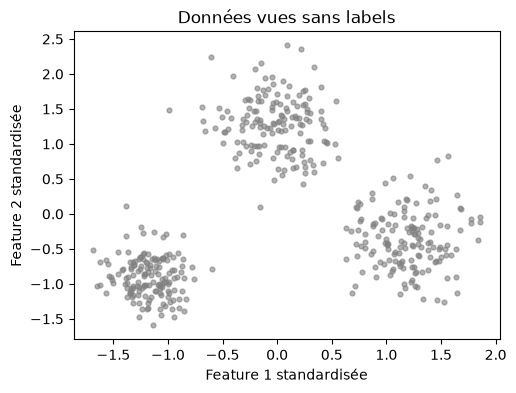

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

blobs, _ = make_blobs(n_samples=450, centers=[(-3, -2), (0, 2), (3, -1)], cluster_std=[0.55, 0.8, 0.7], random_state=13)
scaled_blobs = StandardScaler().fit_transform(blobs)
print('shape des observations :', scaled_blobs.shape)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(scaled_blobs[:, 0], scaled_blobs[:, 1], s=12, alpha=0.6, color='gray')
ax.set(xlabel='Feature 1 standardisée', ylabel='Feature 2 standardisée', title='Données vues sans labels')
plt.show()

## 2. K-Means : une itération faite avec NumPy

K-Means alterne deux opérations : assigner chaque point au centre le plus proche, puis déplacer chaque centre vers la moyenne des points assignés. L'objectif est l'**inertie** $J=\sum_i ||x_i-\mu_{c_i}||_2^2$. Elle ne tient pas compte des labels et favorise des groupes compacts autour de centres.

Pour les quatre points `(0,0),(0,2),(8,8),(8,10)` et les centres initiaux `(0,0),(8,8)`, une mise à jour doit mener aux centres `(0,1)` et `(8,9)`.

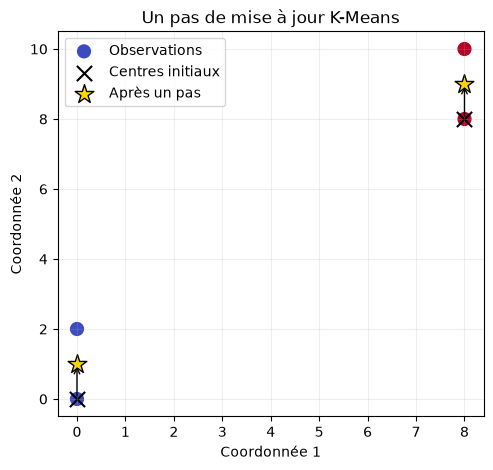

In [ ]:
tiny_points = np.array([[0., 0.], [0., 2.], [8., 8.], [8., 10.]])
initial_centers = np.array([[0., 0.], [8., 8.]])
distances = np.linalg.norm(tiny_points[:, None, :] - initial_centers[None, :, :], axis=2)
assigned = distances.argmin(axis=1)
updated_centers = np.array([tiny_points[assigned == group].mean(axis=0) for group in range(2)])
print('distances (4 points × 2 centres) :\n', distances.round(2))
print('groupes :', assigned, '| centres mis à jour :', updated_centers.tolist())
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(tiny_points[:, 0], tiny_points[:, 1], c=assigned, cmap='coolwarm', s=85, label='Observations')
ax.scatter(initial_centers[:, 0], initial_centers[:, 1], marker='x', c='black', s=120, label='Centres initiaux')
ax.scatter(updated_centers[:, 0], updated_centers[:, 1], marker='*', c='gold', edgecolor='black', s=200, label='Après un pas')
for before, after in zip(initial_centers, updated_centers):
    ax.annotate('', xy=after, xytext=before, arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set(xlabel='Coordonnée 1', ylabel='Coordonnée 2', title='Un pas de mise à jour K-Means')
ax.legend(); ax.grid(alpha=0.2); plt.show()

## 3. K-Means avec scikit-learn

`n_init=10` répète des initialisations et conserve la meilleure inertie. L'inertie baisse toujours si l'on augmente assez le nombre de centres ; elle ne suffit donc pas à choisir `k`. Le coefficient de silhouette compare distance au groupe propre et aux autres groupes ; il a aussi des limites lorsque les formes sont non convexes ou les densités très différentes.

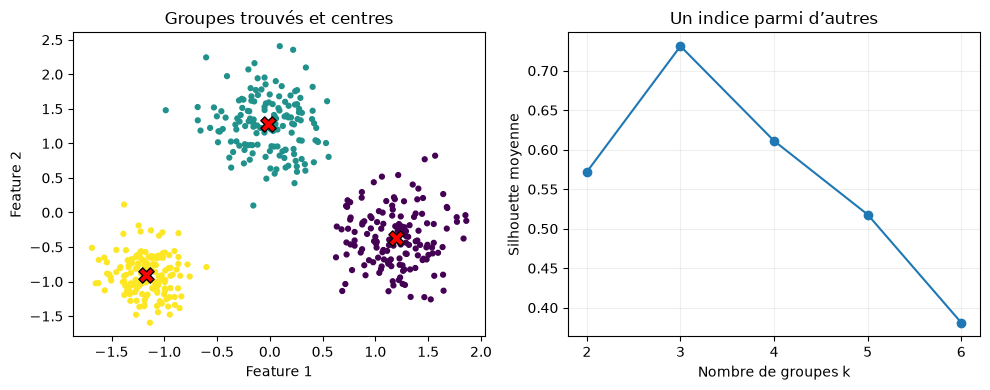

In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=13).fit(scaled_blobs)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(scaled_blobs[:, 0], scaled_blobs[:, 1], c=kmeans.labels_, cmap='viridis', s=12)
axes[0].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker='X', c='red', edgecolor='black', s=120)
axes[0].set(title='Groupes trouvés et centres', xlabel='Feature 1', ylabel='Feature 2')
choices = [2, 3, 4, 5, 6]
silhouettes = [silhouette_score(scaled_blobs, KMeans(n_clusters=k, n_init=10, random_state=13).fit_predict(scaled_blobs)) for k in choices]
axes[1].plot(choices, silhouettes, 'o-'); axes[1].set(xticks=choices, xlabel='Nombre de groupes k', ylabel='Silhouette moyenne', title='Un indice parmi d’autres')
axes[1].grid(alpha=0.2); plt.tight_layout(); plt.show()
print('inertie k=3 :', round(kmeans.inertia_, 1), '| silhouette k=3 :', round(silhouettes[choices.index(3)], 3))

## 4. DBSCAN : densité et bruit

DBSCAN relie les points de régions denses. `eps` fixe le rayon du voisinage et `min_samples` le nombre de points requis pour qu'une zone soit considérée dense. Le label `-1` désigne les points jugés *bruit* ; il ne signifie pas forcément une erreur de données. Le résultat dépend fortement des distances et des paramètres.

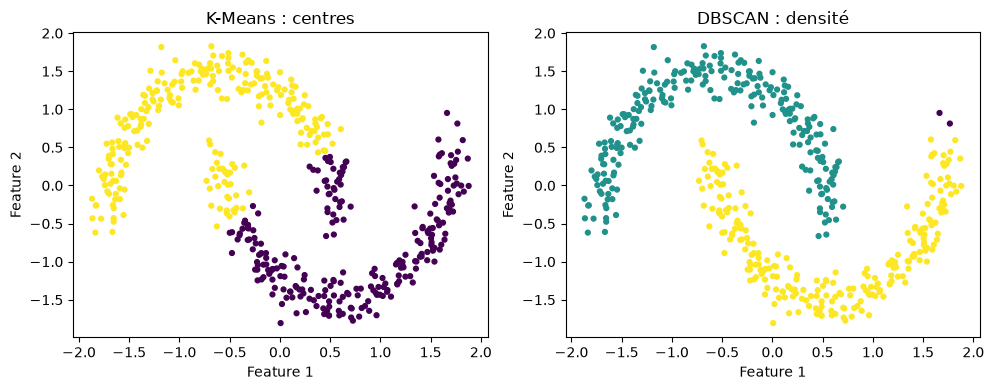

In [ ]:
moons, _ = make_moons(n_samples=500, noise=0.08, random_state=4)
scaled_moons = StandardScaler().fit_transform(moons)
moon_kmeans = KMeans(n_clusters=2, n_init=10, random_state=4).fit_predict(scaled_moons)
moon_dbscan = DBSCAN(eps=0.23, min_samples=6).fit_predict(scaled_moons)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, labels, title in zip(axes, [moon_kmeans, moon_dbscan], ['K-Means : centres', 'DBSCAN : densité']):
    ax.scatter(scaled_moons[:, 0], scaled_moons[:, 1], c=labels, cmap='viridis', s=12)
    ax.set(xlabel='Feature 1', ylabel='Feature 2', title=title)
plt.tight_layout(); plt.show()
print('DBSCAN groupes (hors bruit) :', len(set(moon_dbscan) - {-1}), '| observations bruit :', int(np.sum(moon_dbscan == -1)))

## 5. PCA : conserver de la variance dans moins de dimensions

PCA centre les variables puis cherche les directions orthogonales de plus grande variance. Pour une matrice `X` de forme `(n,p)`, une projection sur `q` composantes a la forme `(n,q)`. La `explained_variance_ratio_` mesure la part de variance de l'échantillon représentée par chaque axe. PCA ne sait rien de la cible : une direction de faible variance peut être utile pour prédire.

Iris est fourni avec scikit-learn. Les couleurs servent ici seulement à interpréter la projection après `fit`; PCA reçoit exclusivement les features.

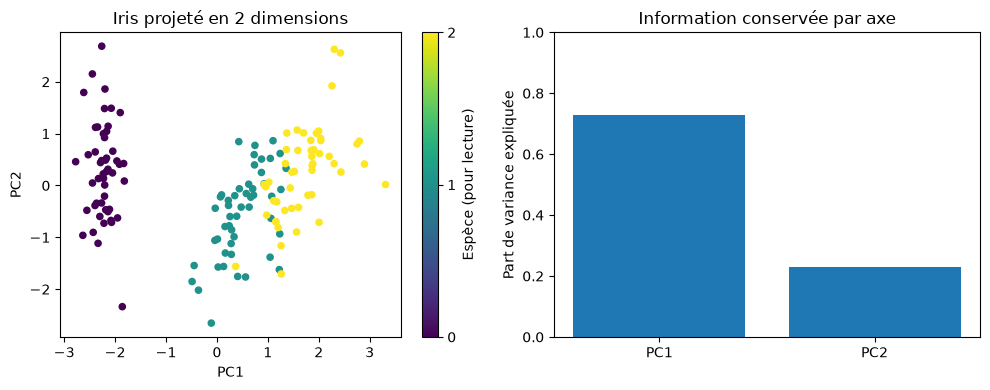

In [ ]:
iris = load_iris(as_frame=True)
iris_features = iris.data
iris_scaled = StandardScaler().fit_transform(iris_features)
pca = PCA(n_components=2).fit(iris_scaled)
projected = pca.transform(iris_scaled)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
scatter = axes[0].scatter(projected[:, 0], projected[:, 1], c=iris.target, cmap='viridis', s=20)
axes[0].set(xlabel='PC1', ylabel='PC2', title='Iris projeté en 2 dimensions')
fig.colorbar(scatter, ax=axes[0], ticks=[0, 1, 2], label='Espèce (pour lecture)')
axes[1].bar(['PC1', 'PC2'], pca.explained_variance_ratio_)
axes[1].set(ylim=(0, 1), ylabel='Part de variance expliquée', title='Information conservée par axe')
plt.tight_layout(); plt.show()
print('dimensions avant/après :', iris_scaled.shape, projected.shape)
print('part totale sur deux axes :', round(pca.explained_variance_ratio_.sum(), 3))

## 6. Expérience : la sensibilité de `eps`

Changer `eps` modifie la connectivité des voisinages. Un petit rayon peut classer beaucoup de points en bruit ; un grand rayon peut fusionner les groupes. La figure ci-dessous garde les mêmes observations et ne change qu'un paramètre.

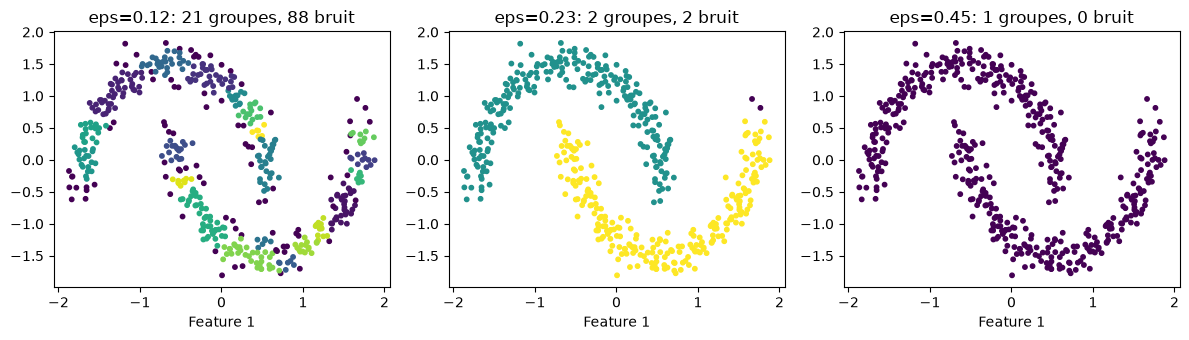

In [ ]:
radii = [0.12, 0.23, 0.45]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, radius in zip(axes, radii):
    labels = DBSCAN(eps=radius, min_samples=6).fit_predict(scaled_moons)
    group_count = len(set(labels) - {-1})
    noise_count = int(np.sum(labels == -1))
    ax.scatter(scaled_moons[:, 0], scaled_moons[:, 1], c=labels, cmap='viridis', s=10)
    ax.set(title=f'eps={radius}: {group_count} groupes, {noise_count} bruit', xlabel='Feature 1')
plt.tight_layout(); plt.show()

## À retenir, limites et exercices

- K-Means résume des groupes autour de centres et impose `k`; DBSCAN privilégie les régions denses et peut marquer du bruit.
- PCA résume des directions de variance, sans utiliser les labels. Pour une tâche supervisée, mettre `StandardScaler` et `PCA` dans une pipeline ajustée uniquement sur chaque train/fold.
- Un regroupement visuellement plaisant ne démontre pas que des catégories réelles existent. La mesure de distance et le contexte métier guident l'interprétation.

**Easy :** reproduire la première itération K-Means pour trois centres. **Medium :** changer l'échelle d'une colonne et comparer les groupes avant/après scaling. **Hard :** choisir une métrique et un protocole de stabilité sur plusieurs graines, puis expliquer pourquoi le meilleur score ne garantit pas un sens métier.